# **TUGAS 1 PENGANTAR DATA MINING**

Nama  : Cheisa Billy Putra Antoni

NIM   : 25/566096/PA/23888

Kelas : B

# **Nomor 1: Pre-processing Data & Exploratory Data Analysis**

Anda adalah seorang **Data Analyst** yang bekerja di sebuah perusahaan media streaming digital terkemuka (**StreamVerse**). Perusahaan ingin memahami bagaimana kebiasaan menonton pengguna (*streaming behavior*), performa kualitas layanan jaringan (*buffering*), biaya langganan, dan interaksi *customer support* memengaruhi kepuasan pengguna serta risiko berhenti berlangganan (*churn risk*). Untuk mendukung pengembangan model *machine learning* prediktif dan strategi retensi pengguna, Anda diminta untuk melakukan eksplorasi data (*Exploratory Data Analysis/EDA*) serta serangkaian *data preprocessing* guna mempersiapkan dataset agar bersih, konsisten, dan siap digunakan dalam pemodelan.

Dataset yang digunakan berisi informasi terkait aktivitas akun pengguna, durasi menonton, platform perangkat, paket langganan, kualitas tayangan, hingga indikator produktivitas dan kepuasan pelanggan. Melalui analisis ini, diharapkan dapat ditemukan pola dan wawasan yang dapat mendukung strategi retensi pengguna dan peningkatan kualitas layanan.

Dataset dapat diakses pada file berikut: [Streaming Dataset](https://drive.google.com/drive/folders/1zsUBFBMr2rgWRjijUDrKwS_3qfPGacEQ?usp=sharing)

**Keterangan Variabel**

* `customer_id`: ID unik pelanggan
* `age`: Usia pelanggan (tahun)
* `gender`: Jenis kelamin pelanggan
* `subscription_plan`: Paket langganan yang digunakan
* `monthly_subscription_fee_usd`: Biaya langganan per bulan (USD)
* `payment_method`: Metode pembayaran yang digunakan
* `daily_streaming_hours`: Rata-rata durasi menonton streaming per hari (jam)
* `primary_device`: Perangkat utama yang digunakan untuk streaming
* `content_genre_favorite`: Genre konten yang paling sering ditonton
* `watch_time_late_night_hours`: Durasi menonton pada larut malam per hari (jam)
* `offline_downloads_monthly`: Jumlah konten yang diunduh untuk tontonan offline per bulan
* `number_of_profiles_shared`: Jumlah profil pengguna yang berbagi akun
* `buffering_events_weekly`: Frekuensi kejadian buffering atau lag per minggu
* `customer_support_tickets`: Jumlah tiket keluhan / komplain ke layanan pelanggan (6 bulan terakhir)
* `student_gpa`: Nilai Indeks Prestasi Kumulatif (IPK)
* `work_productivity_score`: Skor produktivitas kerja harian pelanggan (skala 1 - 10)
* `satisfaction_score`: Tingkat kepuasan pengguna terhadap layanan streaming
* `streaming_quality_preference`: Preferensi resolusi tayangan yang dipilih (SD 480p, HD 720p, FHD 1080p, 4K UHD)
* `tenure_months`: Lama waktu telah menjadi pelanggan (bulan)
* `churn_risk_level`: Tingkat risiko pelanggan berhenti berlangganan (Low, Moderate, High)

## **Import Library**

In [445]:
# Import Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [446]:
# Configuration
pd.set_option('display.max_columns', None)
sns.set_context('notebook')
sns.set_style('whitegrid')
sns.set_palette('tab10')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11

## **Input Data**

In [447]:
# Input Data
df = pd.read_csv('../data/Data Nomor 1 - Tugas 1 PDM.csv')
df.head()

,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level
0,CUST-1753,23,Male,Premium,18.99,EWALLET,3.73,smart tv,action,2.14,1,5,7,5,NaN,8.5,Very Dissatisfied,4K UHD,7,High
1,CUST-1520,50,FEMALE,standard,13.99,e-wallet,4.25,SMART TV,Drama,2.26,2,3,4,0,NaN,3.2,Satisfied,4K UHD,9,Low
2,CUST-1211,39,MALE,PREMIUM,18.99,EWALLET,5.25,Mobile,ACTION,1.73,20,3,10,4,NaN,8.7,Dissatisfied,FHD (1080p),48,High
3,CUST-1612,18,Male,Basic,8.99,E-Wallet,3.51,Smart TV,DRAMA,0.09,6,1,5,0,NaN,6.9,Neutral,SD (480p),9,Moderate
4,CUST-1915,39,female,STANDARD,13.99,Bank Transfer,5.35,MOBILE,Sci-Fi,1.62,19,2,2,2,NaN,6.2,Neutral,4K UHD,1,Moderate


---

## **Exploratory Data Analysis dan Data Cleaning**

Lakukan Exploratory Data Analysis (EDA) pada dataset yang diberikan untuk memahami karakteristik data, kemudian lanjutkan dengan proses data cleaning. Adapun langkah-langkah yang perlu dilakukan adalah sebagai berikut:

1. **Memahami Karakteristik Data**: Tampilkan informasi umum dataset (jumlah data, tipe data, dll.) serta lakukan analisis statistika deskriptif untuk variabel kategorik dan numerik. Berikan insight yang Anda temukan.

2. **Pemeriksaan dan Penanganan Duplikasi Data**: Identifikasi apakah terdapat data yang terduplikasi, kemudian lakukan penanganan yang sesuai, serta jelaskan alasan penggunaan teknik tersebut.

3. **Pemeriksaan dan Perbaikan Inconsistent Data (Kesalahan Format)**: Identifikasi data yang tidak konsisten atau memiliki kesalahan format (termasuk nilai anomali/tidak masuk akal seperti nilai negatif pada usia), lalu lakukan perbaikan agar data menjadi seragam dan sesuai.

4. **Pemeriksaan dan Penanganan Outlier**: Identifikasi nilai ekstrem (outlier) pada variabel numerik (seperti durasi menonton per hari yang tidak wajar atau biaya langganan yang tidak logis) dan lakukan penanganan yang diperlukan. Sertakan alasan pemilihan metode yang digunakan.

5. **Pemeriksaan dan Penanganan Missing Values**: Identifikasi nilai yang hilang (missing values) dan lakukan penanganan yang sesuai. Pastikan penanganan dilakukan setelah memahami pola data agar tidak terjadi kesalahan imputasi (perhatikan keterkaitan atribut dengan tipe paket langganan responden). Sertakan alasan pemilihan metode yang digunakan.

---

### **[1. Karakteristik Data]**

In [448]:
# Karakteristik Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   customer_id                   1015 non-null   object 
 1   age                           1015 non-null   int64  
 2   gender                        1015 non-null   object 
 3   subscription_plan             1015 non-null   object 
 4   monthly_subscription_fee_usd  1015 non-null   float64
 5   payment_method                1015 non-null   object 
 6   daily_streaming_hours         1015 non-null   float64
 7   primary_device                1015 non-null   object 
 8   content_genre_favorite        1015 non-null   object 
 9   watch_time_late_night_hours   1015 non-null   float64
 10  offline_downloads_monthly     1015 non-null   int64  
 11  number_of_profiles_shared     1015 non-null   int64  
 12  buffering_events_weekly       1015 non-null   int64  
 13  cus

**Interpretasi:**
- Seluruh data awal memiliki 1015 baris dan 20 kolom.
- Memiliki tipe data yang beragam, mulai dari numerik berupa int64 dan float64 dan juga kategorikal berupa object atau string.

In [449]:
# Statistik Deskriptif Numerik
df.describe()

,age,monthly_subscription_fee_usd,daily_streaming_hours,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,tenure_months
count,1015.000000,1015.000000,1015.000000,1015.000000,1015.000000,1015.000000,1015.000000,1015.000000,154.000000,861.000000,1015.000000
mean,30.608867,15.397025,3.644079,1.306611,8.562562,2.256158,5.221675,1.216749,3.110000,6.784088,17.243350
std,10.512213,49.486703,2.499251,0.903184,6.731522,1.267637,2.320716,1.309318,0.507404,1.744084,13.992563
min,-38.000000,-18.990000,-4.020000,0.000000,0.000000,1.000000,0.000000,0.000000,2.150000,1.000000,1.000000
25%,24.000000,8.990000,2.640000,0.570000,3.000000,1.000000,4.000000,0.000000,2.712500,5.700000,6.000000
50%,31.000000,13.990000,3.490000,1.180000,6.000000,2.000000,5.000000,1.000000,3.200000,6.800000,13.000000
75%,37.000000,13.990000,4.340000,1.915000,14.000000,3.000000,7.000000,2.000000,3.497500,8.000000,26.000000
max,60.000000,999.000000,42.000000,3.910000,31.000000,5.000000,14.000000,8.000000,3.920000,10.000000,48.000000


**Interpretasi:**
- Statistika deskriptif untuk data numerik akan mengukur nilai pusat maupun sebaran data, seperti jumlah data, rata-rata, standar deviasi, nilai minimum, nilai maksimum, kuartil, dll.
- Ditemukan bahwa kolom monthly_subscription_fee_usd memiliki nilai maksimum yang sangat besar, yakni di angka 999 yang dimana jauh dari rata-ratanya.
- Kolom customer_support_tickets memiliki rata-rata yang paling kecil dari pada kolom lainnya, yakni hanya sebesar 1.216749.

In [450]:
# Statistik Deskriptif Kategori
categorical_columns = df.select_dtypes(include=['object']).columns
categorical_stats = pd.DataFrame(columns=['Column', 'Unique Values', 'Min Value', 'Max Value', 'Most Frequent Value', 'Frequency'])
for col in categorical_columns:
    most_frequent_value = df[col].mode()[0]
    frequency = df[col].value_counts().iloc[0]
    categorical_stats = categorical_stats._append({
        'Column': col,
        'Unique Values': df[col].nunique(),
        'Min Value': df[col].min(),
        'Max Value': df[col].max(),
        'Most Frequent Value': most_frequent_value,
        'Frequency': frequency
    }, ignore_index=True)
categorical_stats

,Column,Unique Values,Min Value,Max Value,Most Frequent Value,Frequency
0,customer_id,1000,CUST-1001,CUST-2000,CUST-1341,2
1,gender,17,Male,other,FEMALE,96
2,subscription_plan,20,Basic,student,standard,83
3,payment_method,20,CREDIT CARD,paylater,Credit Card,82
4,primary_device,20,Mobile,tablet,Smart TV,105
5,content_genre_favorite,25,Action,sci-fi,action,81
6,satisfaction_score,5,Dissatisfied,Very Satisfied,Neutral,405
7,streaming_quality_preference,4,4K UHD,SD (480p),FHD (1080p),316
8,churn_risk_level,3,High,Moderate,High,366


**Interpretasi:**
- Statistika deskriptif untuk data kategorikal menampilkan jumlah nilai unik, nilai kategori sesuai alfabetis awal dan akhir, dan nilai unik paling banyak muncul lengkap dengan frekuensinya
- Kolom customer_id	memiliki 1000 nilai unik yang dimana seharusnya adalah 1050, sesuai dengan jumlah baris data. Hal ini berarti terdeteksi adalah duplikat pada kolom tersebut.
- Kolom age memiliki 17 nilai unik yang dimana secara logika tidak benar.
- Kolom-kolom lainnya pun juga memiliki jumlah nilai unik yang cukup banyak. Hal ini menjadi indikasi awal adanya kesalahan format penulisan sehingga menyebabkan nilai uniknya menjadi lebih beragam.

### **[2. Pemeriksaan dan Penanganan Duplikasi Data]**

In [451]:
# Data Duplikat Pada Semua Kolom
duplicate_data = df[df.duplicated(keep=False)]
duplicate_data.sort_values(df.columns.tolist(), inplace=True)
duplicate_data.head()

/tmp/ipykernel_92946/1571939223.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  duplicate_data.sort_values(df.columns.tolist(), inplace=True)


,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level
125,CUST-1341,39,Male,Standard,13.99,E-Wallet,3.02,Smart TV,action,0.09,2,3,2,2,NaN,6.9,Neutral,FHD (1080p),26,Low
531,CUST-1341,39,Male,Standard,13.99,E-Wallet,3.02,Smart TV,action,0.09,2,3,2,2,NaN,6.9,Neutral,FHD (1080p),26,Low
404,CUST-1377,44,FEMALE,Premium,18.99,EWALLET,5.37,mobile,documentary,2.16,23,5,9,2,NaN,6.4,Dissatisfied,FHD (1080p),2,High
794,CUST-1377,44,FEMALE,Premium,18.99,EWALLET,5.37,mobile,documentary,2.16,23,5,9,2,NaN,6.4,Dissatisfied,FHD (1080p),2,High
300,CUST-1418,21,Female,Student,4.99,E-Wallet,2.17,PC,anime,0.79,12,1,1,0,2.84,NaN,Very Satisfied,HD (720p),11,Low


In [452]:
# Penanganan Data Duplikat
df_processed = df.drop_duplicates()
display(df_processed.head())
display(df_processed.info())

,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level
0,CUST-1753,23,Male,Premium,18.99,EWALLET,3.73,smart tv,action,2.14,1,5,7,5,NaN,8.5,Very Dissatisfied,4K UHD,7,High
1,CUST-1520,50,FEMALE,standard,13.99,e-wallet,4.25,SMART TV,Drama,2.26,2,3,4,0,NaN,3.2,Satisfied,4K UHD,9,Low
2,CUST-1211,39,MALE,PREMIUM,18.99,EWALLET,5.25,Mobile,ACTION,1.73,20,3,10,4,NaN,8.7,Dissatisfied,FHD (1080p),48,High
3,CUST-1612,18,Male,Basic,8.99,E-Wallet,3.51,Smart TV,DRAMA,0.09,6,1,5,0,NaN,6.9,Neutral,SD (480p),9,Moderate
4,CUST-1915,39,female,STANDARD,13.99,Bank Transfer,5.35,MOBILE,Sci-Fi,1.62,19,2,2,2,NaN,6.2,Neutral,4K UHD,1,Moderate


<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 1014
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   customer_id                   1000 non-null   object 
 1   age                           1000 non-null   int64  
 2   gender                        1000 non-null   object 
 3   subscription_plan             1000 non-null   object 
 4   monthly_subscription_fee_usd  1000 non-null   float64
 5   payment_method                1000 non-null   object 
 6   daily_streaming_hours         1000 non-null   float64
 7   primary_device                1000 non-null   object 
 8   content_genre_favorite        1000 non-null   object 
 9   watch_time_late_night_hours   1000 non-null   float64
 10  offline_downloads_monthly     1000 non-null   int64  
 11  number_of_profiles_shared     1000 non-null   int64  
 12  buffering_events_weekly       1000 non-null   int64  
 13  customer

None

**Interpretasi:**
- Diketahui bahwa data duplikat dapat terdeteksi menggunakan kolom customer_id. Kolom ini harus unik dan tidak boleh duplikat.
- Terdapat total 15 kolom customer_id yang duplikat.
- Penanganan data duplikat yang dilakukan ada dengan cara membuang baris yang memuat customer_id yang duplikat tersebut.
- Kolom customer_id yang duplikat dianggap suatu kesalahan input, sehingga penanganan dengan cara di drop adalah pilihan yang tepat.

### **[3. Pemeriksaan dan Perbaikan Inconsistent Data (Kesalahan Format)]**

In [453]:
# EDA Untuk Inkonsistensi Format Data Kategorikal
cat_inconsistency_cols = [
    'gender', 
    'subscription_plan', 
    'payment_method', 
    'primary_device', 
    'content_genre_favorite'
]
for col in cat_inconsistency_cols:
    raw_unique = df_processed[col].nunique()
    samples = df_processed[col].value_counts().head(raw_unique).index
    vector = ", ".join([repr(val) for val in samples])
    print(f"[Kolom: {col}]")
    print(f"• Unique Raw: {raw_unique}")
    print(f"• Sample: [{vector}]")
    print("\n")

[Kolom: gender]
• Unique Raw: 17
• Sample: ['FEMALE ', ' female', 'FEMALE', 'female ', 'Male', 'MALE', ' Male', 'Female ', 'male', 'Male ', 'Female', 'male ', 'Other', 'Other ', 'OTHER', ' Other', 'other']


[Kolom: subscription_plan]
• Unique Raw: 20
• Sample: ['standard', 'Standard ', 'basic', 'BASIC', ' standard', 'Basic', 'STANDARD', 'Standard', 'premium ', ' Basic', 'basic ', ' student', 'premium', 'PREMIUM', ' Premium', 'Premium', 'STUDENT', 'student', 'Student ', 'Student']


[Kolom: payment_method]
• Unique Raw: 20
• Sample: ['Credit Card ', 'Credit Card', 'credit card', ' CREDIT CARD', 'CreditCard', 'e-wallet', 'E-Wallet', 'Ewallet', ' E-Wallet', 'Bank Transfer', 'E-Wallet ', 'EWALLET', 'Bank Transfer ', 'BANK TRANSFER', 'bank transfer', 'paylater', 'PAYLATER', 'PayLater', ' PayLater', 'Paylater ']


[Kolom: primary_device]
• Unique Raw: 20
• Sample: ['Smart TV ', 'smart tv', 'MOBILE', 'mobile', 'SMART TV', 'Smart TV', 'mobile ', ' Mobile', ' Smart TV', 'Mobile', 'laptop/pc', 

In [454]:
# Penanganan Inkonsistensi Format Pada Data Kategorikal
for col in cat_inconsistency_cols:
    df_processed[col] = df_processed[col].astype(str).str.strip().str.title()
mapping_payment = {
    'Creditcard': 'Credit Card',
    'Ewallet': 'E-Wallet'
}
mapping_device = {
    'Pc': 'Laptop/PC',
    'Laptop/Pc': 'Laptop/PC',
    'Smart Tv': 'Smart TV'
}
mapping_genre = {
    'Scifi': 'Sci-Fi',
    'Sci-fi': 'Sci-Fi'
}
df_processed['payment_method'] = df_processed['payment_method'].replace(mapping_payment)
df_processed['primary_device'] = df_processed['primary_device'].replace(mapping_device)
df_processed['content_genre_favorite'] = df_processed['content_genre_favorite'].replace(mapping_genre)

/tmp/ipykernel_92946/3861439068.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed[col] = df_processed[col].astype(str).str.strip().str.title()
/tmp/ipykernel_92946/3861439068.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed[col] = df_processed[col].astype(str).str.strip().str.title()
/tmp/ipykernel_92946/3861439068.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

**Interpretasi:**
- Penanganan format penulisan pada data kategori cukup dengan memperbaiki penulisan yang benar.
- Penulisan seluruh nilai serentak menggunakan awalan huruf kapital.
- Kemudian penghapusan spasi berlebih.
- Memperlakukan beberapa kategori pengecualian, seperti 'Ewallet' menjadi 'E-Wallet', 'Laptop/Pc' menjadi 'Laptop/PC', dll.

In [455]:
# EDA Untuk Anomali Data Numerik
numerical_anomalies = {
    'age': df_processed['age'] < 0,
    'monthly_subscription_fee_usd': df_processed['monthly_subscription_fee_usd'] < 0,
    'daily_streaming_hours': (df_processed['daily_streaming_hours'] < 0) | (df_processed['daily_streaming_hours'] > 24)
}
for col, condition in numerical_anomalies.items():
    anomalies = df_processed[condition][col]
    total_anomali = len(anomalies)
    samples = anomalies.head(10).tolist()
    vector = ", ".join([str(val) for val in samples])
    print(f"[Kolom: {col}]")
    print(f"• Jumlah Anomali: {total_anomali}")
    print(f"• Sample: [{vector}]")
    print("\n")

[Kolom: age]
• Jumlah Anomali: 8
• Sample: [-30, -27, -34, -35, -16, -37, -38, -29]


[Kolom: monthly_subscription_fee_usd]
• Jumlah Anomali: 4
• Sample: [-18.99, -8.99, -13.99, -8.99]


[Kolom: daily_streaming_hours]
• Jumlah Anomali: 9
• Sample: [42.0, -2.65, -3.53, 30.5, -2.54, 34.2, -4.02, 36.8, 28.5]




In [456]:
# Penanganan Anomali Pada Data Numerik
df_processed['age'] = df_processed['age'].abs()
df_processed['monthly_subscription_fee_usd'] = df_processed['monthly_subscription_fee_usd'].abs()
df_processed['daily_streaming_hours'] = df_processed['daily_streaming_hours'].abs()
df_processed = df_processed[df_processed['daily_streaming_hours'] <= 24].reset_index(drop=True)

/tmp/ipykernel_92946/1086316538.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed['age'] = df_processed['age'].abs()
/tmp/ipykernel_92946/1086316538.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed['monthly_subscription_fee_usd'] = df_processed['monthly_subscription_fee_usd'].abs()
/tmp/ipykernel_92946/1086316538.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cav

**Interpretasi:**
- Penanganan anomali pada data numerik adalah dengan mengubah serta membuang nilai.
- Untuk nilai yang negatif pada kolom age dan monthly_subscription_fee_usd wajib diubah ke nilai positif. Hal ini dikarenakan ketidakmungkinan bahwa kolom-kolom tersebut bernilai negatif.
- Khusus untuk kolom daily_streaming_hours, selain mengubah nilai agar menjadi positif juga melakukan drop pada nilai yang lebih dari 24 (> 24). Hal ini tidak lain dan tidak bukan adalah suatu hal yang tidak wajar dalam sehari waktu bisa melebihi 24 jam.

### **[4. Pemeriksaan dan Penanganan Outlier]**

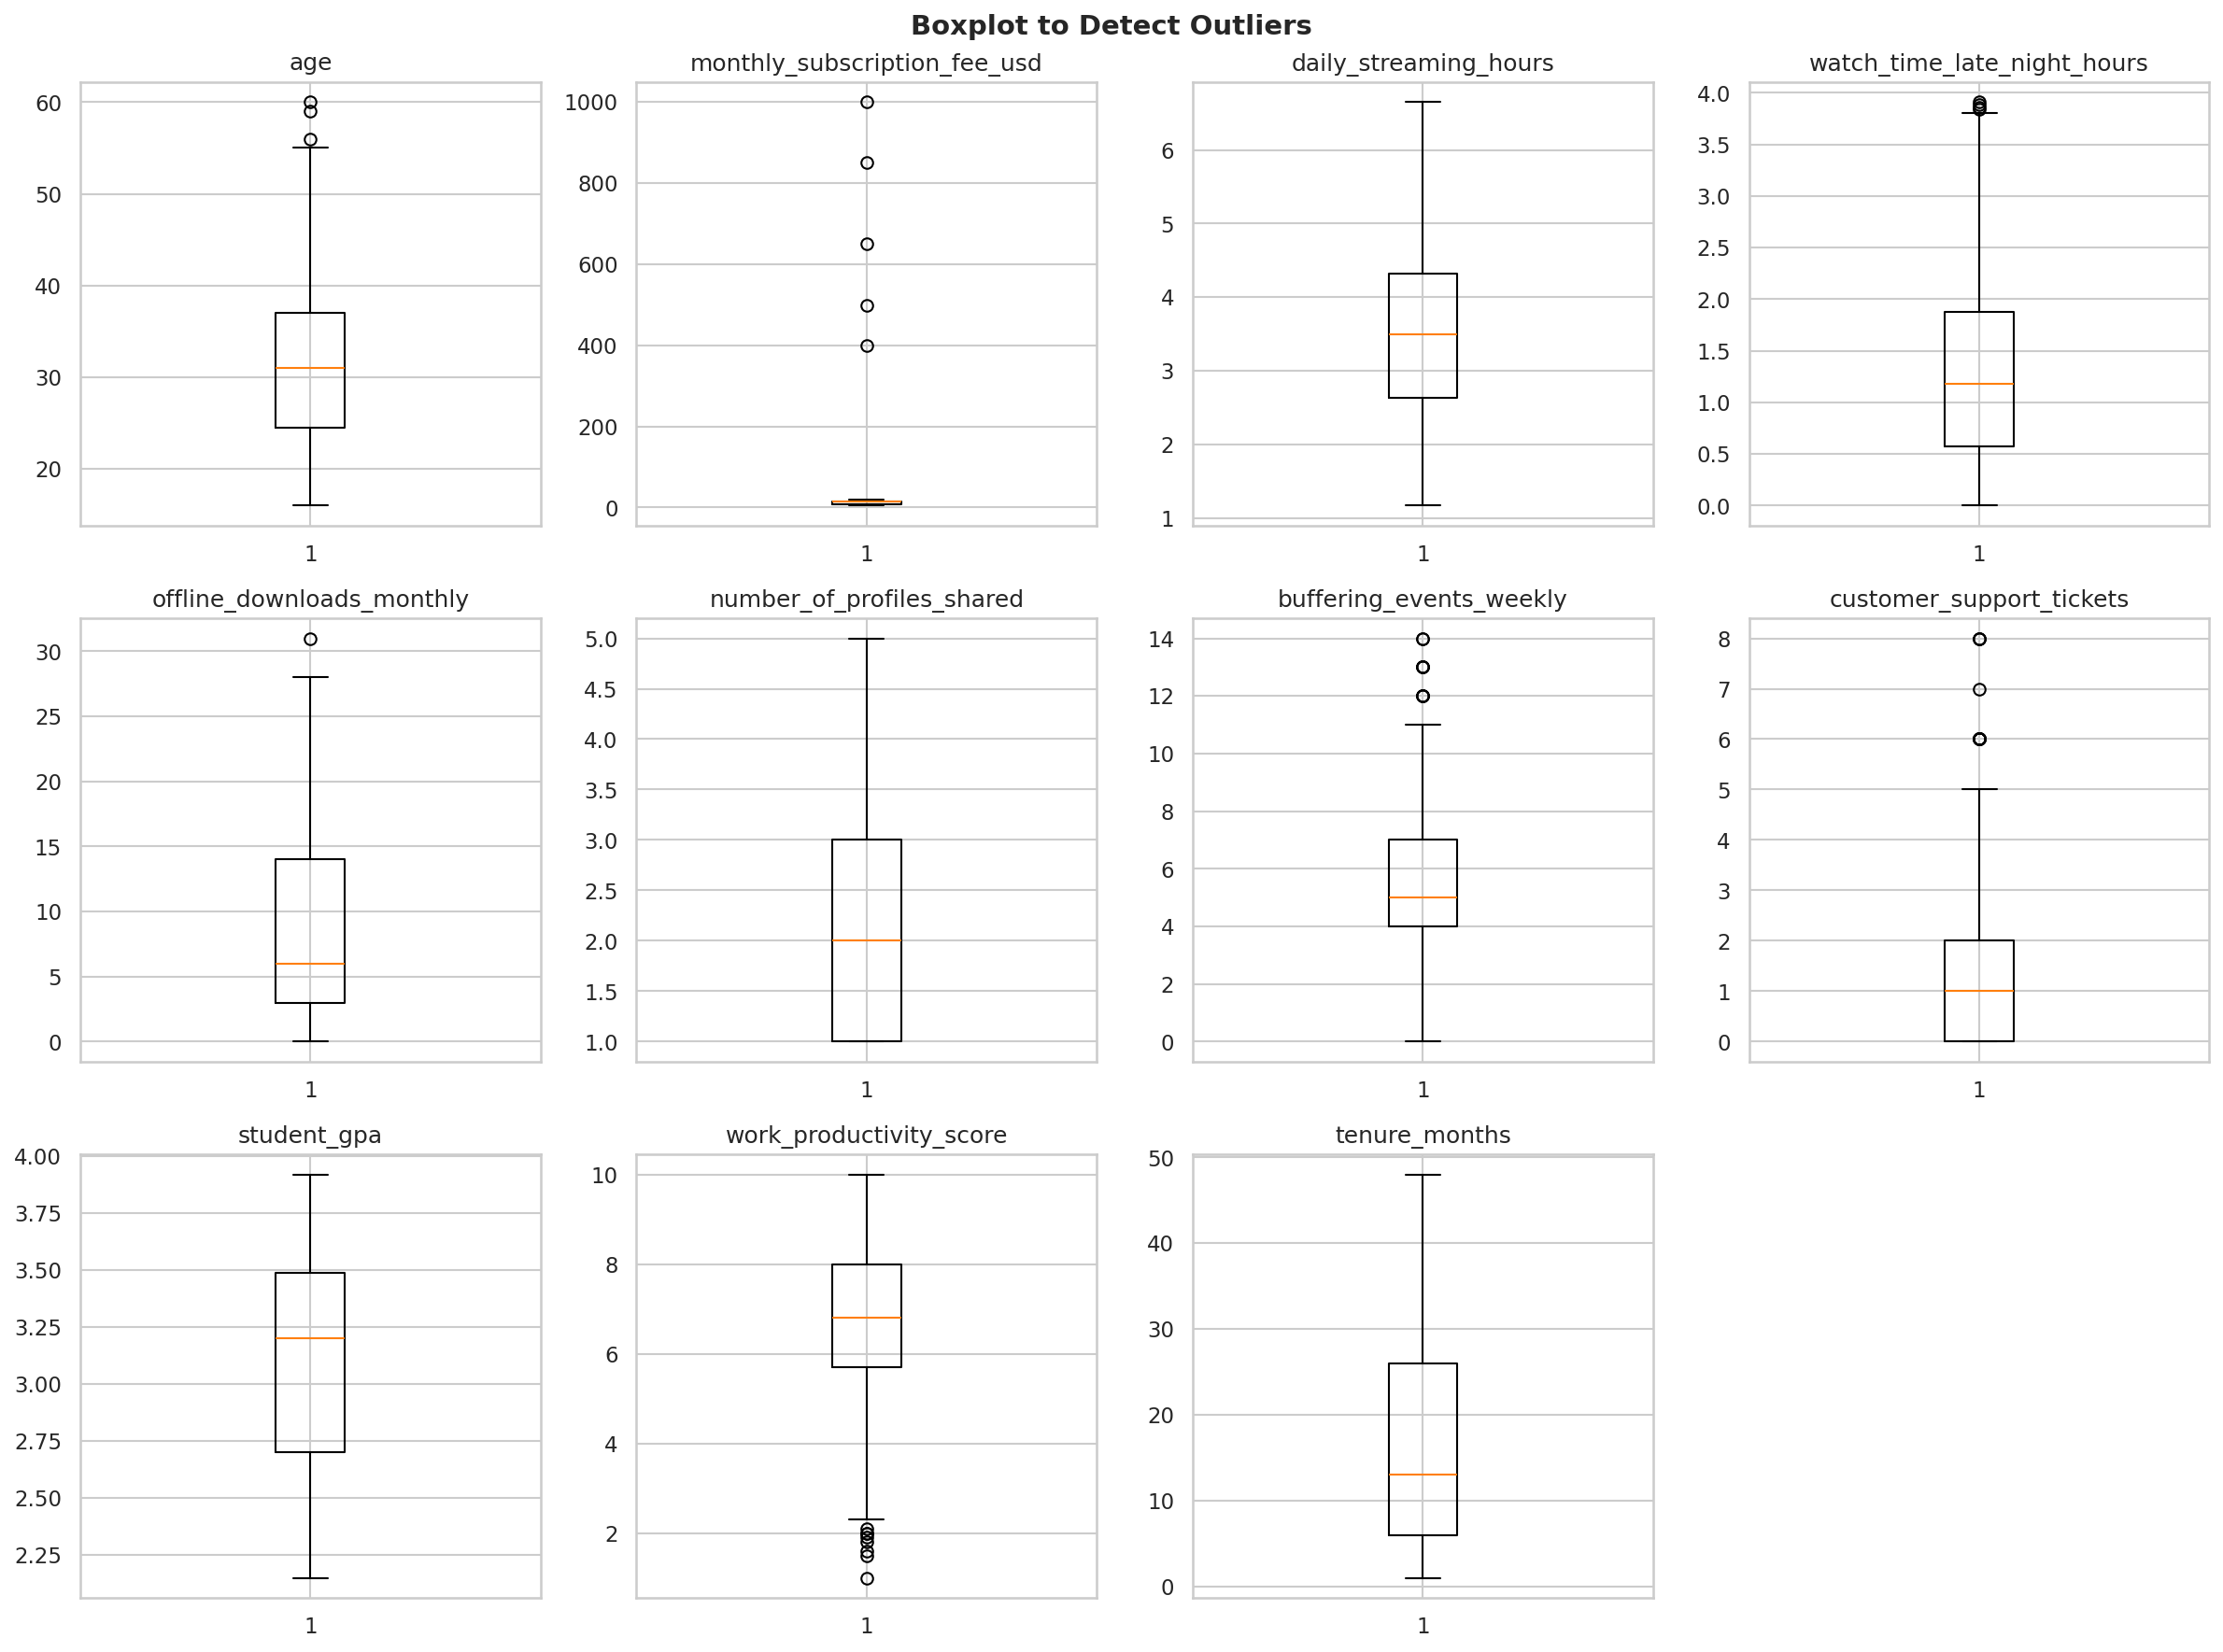

In [457]:
# EDA Untuk Outlier Data Numerik
num_cols = df_processed.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols = df_processed.select_dtypes(include=['int64', 'float64']).columns.tolist()
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, col in enumerate(num_cols):
    axes.flatten()[i].boxplot(df_processed[col].dropna())
    axes.flatten()[i].set_title(col)

fig.delaxes(axes.flatten()[-1])
plt.suptitle('Boxplot to Detect Outliers', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [458]:
# Deteksi Outlier Dengan Metode IQR
target_cols = [
    'age',
    'monthly_subscription_fee_usd',
    'watch_time_late_night_hours',
    'offline_downloads_monthly',
    'buffering_events_weekly',
    'customer_support_tickets',
    'work_productivity_score'
]
iqr_outliers_info = {}
for col in target_cols:
    s = df_processed[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    unique_outliers = sorted(outliers.unique().tolist())
    iqr_outliers_info[col] = {
        'q1': round(q1, 2),
        'q3': round(q3, 2),
        'iqr': round(iqr, 2),
        'lower_bound': round(lower_bound, 2),
        'upper_bound': round(upper_bound, 2),
        'total_outliers': len(outliers),
        'unique_outliers': unique_outliers
    }

for col, info in iqr_outliers_info.items():
    print(f"[Kolom: {col}]")
    print(f"• Batas Bawah    : {info['lower_bound']}")
    print(f"• Batas Atas     : {info['upper_bound']}")
    print(f"• Jumlah Outlier : {info['total_outliers']}")
    print(f"• Nilai Outlier  : {info['unique_outliers']}")
    print("\n")

[Kolom: age]
• Batas Bawah    : 5.75
• Batas Atas     : 55.75
• Jumlah Outlier : 3
• Nilai Outlier  : [56, 59, 60]


[Kolom: monthly_subscription_fee_usd]
• Batas Bawah    : 1.49
• Batas Atas     : 21.49
• Jumlah Outlier : 5
• Nilai Outlier  : [399.0, 499.0, 650.0, 850.0, 999.0]


[Kolom: watch_time_late_night_hours]
• Batas Bawah    : -1.39
• Batas Atas     : 3.83
• Jumlah Outlier : 4
• Nilai Outlier  : [3.84, 3.86, 3.89, 3.91]


[Kolom: offline_downloads_monthly]
• Batas Bawah    : -13.5
• Batas Atas     : 30.5
• Jumlah Outlier : 1
• Nilai Outlier  : [31]


[Kolom: buffering_events_weekly]
• Batas Bawah    : -0.5
• Batas Atas     : 11.5
• Jumlah Outlier : 10
• Nilai Outlier  : [12, 13, 14]


[Kolom: customer_support_tickets]
• Batas Bawah    : -3.0
• Batas Atas     : 5.0
• Jumlah Outlier : 12
• Nilai Outlier  : [6, 7, 8]


[Kolom: work_productivity_score]
• Batas Bawah    : 2.25
• Batas Atas     : 11.45
• Jumlah Outlier : 8
• Nilai Outlier  : [1.0, 1.5, 1.6, 1.8, 1.9, 2.0, 2.1]




**Interpretasi:**
- Diperoleh informasi bahwa terdapat outliers pada kolom age, monthly_subscription_fee_usd, watch_time_late_night_hours, offline_downloads_monthly, buffering_events_weekly, customer_support_tickets, dan work_productivity_score.

In [459]:
# Penanganan Outlier Pada Kolom monthly_subscription_fee_usd
outlier = [399.0, 499.0, 650.0, 850.0, 999.0]
df_processed = df_processed[~df_processed['monthly_subscription_fee_usd'].isin(outlier)].reset_index(drop=True)

**Interpretasi:**
- Penanganan outiers hanya dilakukan pada kolom monthly_subscription_fee_usd yang dimana memiliki outlier paling ekstrem, yaitu 399.0, 499.0, 650.0, 850.0, dan 999.0.
- Sedangkan kolom-kolom lainnya tetap dipertahankan dan tidak di drop karena masih berada di batas wajar dan tidak terlalu jauh.
- Penghindaran dari sekedar drop nilai outlier ini dilakukan agar tidak banyak kehilangan informasi akibat pembuangan data.

### **[5. Pemeriksaan dan Penanganan Missing Values]**

In [460]:
# Cek Missing Values
missing_values = pd.DataFrame({
    'Missing Values': df_processed.isnull().sum(),
    'Percentage': (df_processed.isnull().sum() / len(df_processed)) * 100
}).round(2)
missing_values

,Missing Values,Percentage
customer_id,0,0.00
age,0,0.00
gender,0,0.00
subscription_plan,0,0.00
monthly_subscription_fee_usd,0,0.00
payment_method,0,0.00
daily_streaming_hours,0,0.00
primary_device,0,0.00
content_genre_favorite,0,0.00
watch_time_late_night_hours,0,0.00


**Interpretasi:**
- Diperoleh informasi bahwa terdapat outliers pada kolom student_gpa sebanyak 841 baris	(84.95%) dan kolom work_productivity_score sebanyak 149 baris	(15.05%).

In [461]:
# Penanganan Missing Values Dengan Mean Untuk Kolom student_gpa Dan Median Untuk Kolom work_productivity_score
df_processed['student_gpa'].fillna(df_processed['student_gpa'].mean(), inplace=True)
df_processed['work_productivity_score'].fillna(df_processed['work_productivity_score'].median(), inplace=True)

/tmp/ipykernel_92946/3526473338.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_processed['student_gpa'].fillna(df_processed['student_gpa'].mean(), inplace=True)
/tmp/ipykernel_92946/3526473338.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[c

**Interpretasi:**
- Penanganan outlier dilakukan dengan mengisinya menggunakan nilai mean untuk kolom student_gpa, dan nilai median untuk kolom work_productivity_score.
- Hal ini dilakukan karena kolom work_productivity_score belum terlihat seimbang sebaran datanya, sehingga menggunakan median agar lebih robust.
- Sedangkan kolom student_gpa lebih seimbang dan juga tidak memiliki outlier, sehingga masih aman jika menggunakan mean.

In [462]:
# Tampilan Data Bersih
df_processed.head()

,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level
0,CUST-1753,23,Male,Premium,18.99,E-Wallet,3.73,Smart TV,Action,2.14,1,5,7,5,3.102953,8.5,Very Dissatisfied,4K UHD,7,High
1,CUST-1520,50,Female,Standard,13.99,E-Wallet,4.25,Smart TV,Drama,2.26,2,3,4,0,3.102953,3.2,Satisfied,4K UHD,9,Low
2,CUST-1211,39,Male,Premium,18.99,E-Wallet,5.25,Mobile,Action,1.73,20,3,10,4,3.102953,8.7,Dissatisfied,FHD (1080p),48,High
3,CUST-1612,18,Male,Basic,8.99,E-Wallet,3.51,Smart TV,Drama,0.09,6,1,5,0,3.102953,6.9,Neutral,SD (480p),9,Moderate
4,CUST-1915,39,Female,Standard,13.99,Bank Transfer,5.35,Mobile,Sci-Fi,1.62,19,2,2,2,3.102953,6.2,Neutral,4K UHD,1,Moderate


In [463]:
# Nilai Unik & Frekuensi Data Kategorikal
categorical_columns = df_processed.drop(['customer_id'], axis=1).select_dtypes(include=['object']).columns
for col in categorical_columns:
    unique_values = df_processed[col].unique()
    print(f"[Kolom: {col}]")
    print(f"• Unique Values: {unique_values}")
    print("\n")

[Kolom: gender]
• Unique Values: ['Male' 'Female' 'Other']


[Kolom: subscription_plan]
• Unique Values: ['Premium' 'Standard' 'Basic' 'Student']


[Kolom: payment_method]
• Unique Values: ['E-Wallet' 'Bank Transfer' 'Credit Card' 'Paylater']


[Kolom: primary_device]
• Unique Values: ['Smart TV' 'Mobile' 'Tablet' 'Laptop/PC']


[Kolom: content_genre_favorite]
• Unique Values: ['Action' 'Drama' 'Sci-Fi' 'Anime' 'Comedy' 'Documentary']


[Kolom: satisfaction_score]
• Unique Values: ['Very Dissatisfied' 'Satisfied' 'Dissatisfied' 'Neutral' 'Very Satisfied']


[Kolom: streaming_quality_preference]
• Unique Values: ['4K UHD' 'FHD (1080p)' 'SD (480p)' 'HD (720p)']


[Kolom: churn_risk_level]
• Unique Values: ['High' 'Low' 'Moderate']




---

## **Data Transformation**

Setelah melakukan tahap data cleaning, lakukan proses data transformation untuk mempersiapkan data sebelum digunakan dalam pemodelan. Adapun langkah-langkah yang perlu dilakukan adalah sebagai berikut:

1. **Scaling pada Variabel Numerik**:
Identifikasi variabel numerik yang perlu dilakukan scaling, kemudian terapkan metode yang sesuai. Jelaskan alasan pemilihan metode yang digunakan.

2. **Encoding pada Variabel Kategorik**:
Identifikasi variabel kategorik yang perlu dilakukan encoding, kemudian terapkan teknik yang sesuai. Jelaskan alasan pemilihan metode yang digunakan.

### **[1. Scaling pada Variabel Numerik]**

In [464]:
# Scaling Data Numerik Dengan RobustScaler
from sklearn.preprocessing import RobustScaler

df_scaled = df_processed.copy()
scaler = RobustScaler()
numerical_cols = df_scaled.select_dtypes(include=['int64', 'float64']).columns
df_scaled[numerical_cols] = scaler.fit_transform(df_scaled[numerical_cols])

**Interpretasi:**
- Scaling menggunakan RobustScaler berbasis nilai pusat median dan sebaran IQR.
- Metode ini dipilih karena lebih robust terhadap data yang memiliki banyak outlier karena menggunakan median sebagai pusatnya.

### **[2. Encoding pada Variabel Kategorik]**

In [465]:
# Encoding Data Kategorikal Dengan LabelEncoder Untuk Kolom Nominal Dan OrdinalEncoder Untuk Kolom Ordinal
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder

nominal_cols = ['gender', 'payment_method', 'primary_device', 'content_genre_favorite']
for col in nominal_cols:
    le = LabelEncoder()
    df_scaled[col] = le.fit_transform(df_scaled[col])

ordinal_cols = ['subscription_plan', 'satisfaction_score', 'streaming_quality_preference', 'churn_risk_level']
ordinal_categories = [
    ['Student', 'Basic', 'Standard', 'Premium'],
    ['Very Dissatisfied', 'Dissatisfied', 'Neutral', 'Satisfied', 'Very Satisfied'],
    ['SD (480p)', 'HD (720p)', 'FHD (1080p)', '4K UHD'],
    ['Low', 'Moderate', 'High']
]
oe = OrdinalEncoder(categories=ordinal_categories)
df_scaled[ordinal_cols] = oe.fit_transform(df_scaled[ordinal_cols])

**Interpretasi:**
- Encoding untuk data kategorikal menggunakan LabelEncoding untuk data nonimal dan OrdinalEncoding untuk data ordinal.
- LabelEncoding mengubah nilai tanpa memperhitungkan peringkat, sehingga aman digunakan untuk data nomimal.
- Sedangkan OrdinalEncoding mengubah nilai dengan memperhitungkan peringkat, sehingga lebih bagus digunakan untuk data ordinal.

In [466]:
# Tampilan Data Setelah Encoding
df_scaled.head()

,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level
0,CUST-1753,-0.627451,1,3.0,1.0,2,0.142433,2,0,0.738050,-0.454545,1.5,0.666667,2.0,0.0,0.894737,0.0,3.0,-0.30,2.0
1,CUST-1520,1.490196,0,2.0,0.0,2,0.451039,2,4,0.829828,-0.363636,0.5,-0.333333,-0.5,0.0,-1.894737,3.0,3.0,-0.20,0.0
2,CUST-1211,0.627451,1,3.0,1.0,2,1.044510,1,0,0.424474,1.272727,0.5,1.666667,1.5,0.0,1.000000,1.0,2.0,1.75,2.0
3,CUST-1612,-1.019608,1,1.0,-1.0,2,0.011869,2,4,-0.829828,0.000000,-0.5,0.000000,-0.5,0.0,0.052632,2.0,0.0,-0.20,1.0
4,CUST-1915,0.627451,0,2.0,0.0,0,1.103858,1,5,0.340344,1.181818,0.0,-1.000000,0.5,0.0,-0.315789,2.0,3.0,-0.60,1.0


---

## **[Feature Construction]**

Lakukan feature construction dengan membuat **minimal satu fitur baru** dari atribut yang sudah ada dalam dataset. Jelaskan proses pembentukan fitur tersebut dan relevansinya terhadap analisis perilaku pengguna.

In [467]:
# Fitur 1: Rasio Menonton Larut Malam
df_scaled['late_night_streaming_ratio'] = np.where(
    df_scaled['daily_streaming_hours'] > 0,
    df_scaled['watch_time_late_night_hours'] / df_scaled['daily_streaming_hours'],
    0
)

**Interpretasi:**
- Kolom baru bernama late_night_streaming_ratio (Rasio Menonton Larut Malam).
- Proses Pembentukan: Membagi durasi menonton pada larut malam per hari dengan total durasi menonton harian.
- Relevansi Perilaku Pengguna:Menunjukkan seberapa besar porsi aktivitas menonton pengguna yang dilakukan pada malam/dini hari. Pengguna dengan rasio tinggi ($\ge 50\%$) cenderung memiliki pola konsumsi night-owl, yang berkaitan erat dengan kelompok usia tertentu (misal mahasiswa/pekerja muda) dan pola preferensi konten khusus.

In [468]:
# Fitur 2: Biaya per Jam Menonton Streaming (Estimasi 30 Hari)
df_scaled['cost_per_streaming_hour'] = df_scaled['monthly_subscription_fee_usd'] / (df_scaled['daily_streaming_hours'] * 30 + 1e-5)

**Interpretasi:**
- Kolom baru bernama cost_per_streaming_hour (Biaya per Jam Streaming).
- Proses Pembentukan: Membagi total biaya langganan bulanan dengan perkiraan total jam menonton pengguna dalam satu bulan (30 hari).
- Relevansi Perilaku Pengguna: Mengukur efisiensi biaya (perceived value) dari perspektif pengguna. Jika nilai biaya per jamnya sangat tinggi (misalnya membayar mahal tetapi jarang menonton), pengguna berisiko tinggi merasa tidak rugi untuk membatalkan langganan (Churn Risk).

In [469]:
# Fitur 3: Rasio Tiket Komplain per Bulan Masa Berlangganan
df_scaled['support_tickets_per_tenure_month'] = df_scaled['customer_support_tickets'] / (df_scaled['tenure_months'] + 1e-5)

**Interpretasi:**
- Kolom baru bernama support_tickets_per_tenure_month (Frekuensi Komplain per Bulan Tenure).
- Proses Pembentukan: Membagi jumlah tiket komplain layanan pelanggan dengan masa lama menjadi pelanggan (bulan).
- Relevansi Perilaku Pengguna: Mengukur tingkat "ketidakpuasan relatif" pengguna. Pengguna baru yang langsung mengajukan banyak tiket keluhan dalam kurun waktu singkat memiliki rasio komplain tinggi, yang menjadi indikator kuat potensi churn awal (early-stage churn).

In [470]:
# Tampilan Data Setelah Feature Engineering
df_scaled.head()

,customer_id,age,gender,subscription_plan,monthly_subscription_fee_usd,payment_method,daily_streaming_hours,primary_device,content_genre_favorite,watch_time_late_night_hours,offline_downloads_monthly,number_of_profiles_shared,buffering_events_weekly,customer_support_tickets,student_gpa,work_productivity_score,satisfaction_score,streaming_quality_preference,tenure_months,churn_risk_level,late_night_streaming_ratio,cost_per_streaming_hour,support_tickets_per_tenure_month
0,CUST-1753,-0.627451,1,3.0,1.0,2,0.142433,2,0,0.738050,-0.454545,1.5,0.666667,2.0,0.0,0.894737,0.0,3.0,-0.30,2.0,5.181724,0.234027,-6.666889
1,CUST-1520,1.490196,0,2.0,0.0,2,0.451039,2,4,0.829828,-0.363636,0.5,-0.333333,-0.5,0.0,-1.894737,3.0,3.0,-0.20,0.0,1.839816,0.000000,2.500125
2,CUST-1211,0.627451,1,3.0,1.0,2,1.044510,1,0,0.424474,1.272727,0.5,1.666667,1.5,0.0,1.000000,1.0,2.0,1.75,2.0,0.406386,0.031913,0.857138
3,CUST-1612,-1.019608,1,1.0,-1.0,2,0.011869,2,4,-0.829828,0.000000,-0.5,0.000000,-0.5,0.0,0.052632,2.0,0.0,-0.20,1.0,-69.913002,-2.808254,2.500125
4,CUST-1915,0.627451,0,2.0,0.0,0,1.103858,1,5,0.340344,1.181818,0.0,-1.000000,0.5,0.0,-0.315789,2.0,3.0,-0.60,1.0,0.308323,0.000000,-0.833347


---

## **Data Exploration**

Setelah data dibersihkan dan dilakukan preprocessing, lakukan kembali eksplorasi data.

Buat minimal 3 visualisasi yang dapat membantu dalam memahami karakteristik data tersebut (misalnya distribusi data, hubungan antar variabel, atau perbandingan antar kategori).

Berdasarkan visualisasi yang telah dibuat, jelaskan insight yang diperoleh. Apakah terdapat pola, tren, atau temuan menarik terkait faktor yang memengaruhi kepuasan pengguna dan risiko berhenti berlangganan (*churn risk*)?

In [471]:
# Urutan Kategori
churn_order = ['Low', 'Moderate', 'High']
satisfaction_order = ['Very Dissatisfied', 'Dissatisfied', 'Neutral', 'Satisfied', 'Very Satisfied']
plan_order = ['Student', 'Basic', 'Standard', 'Premium']

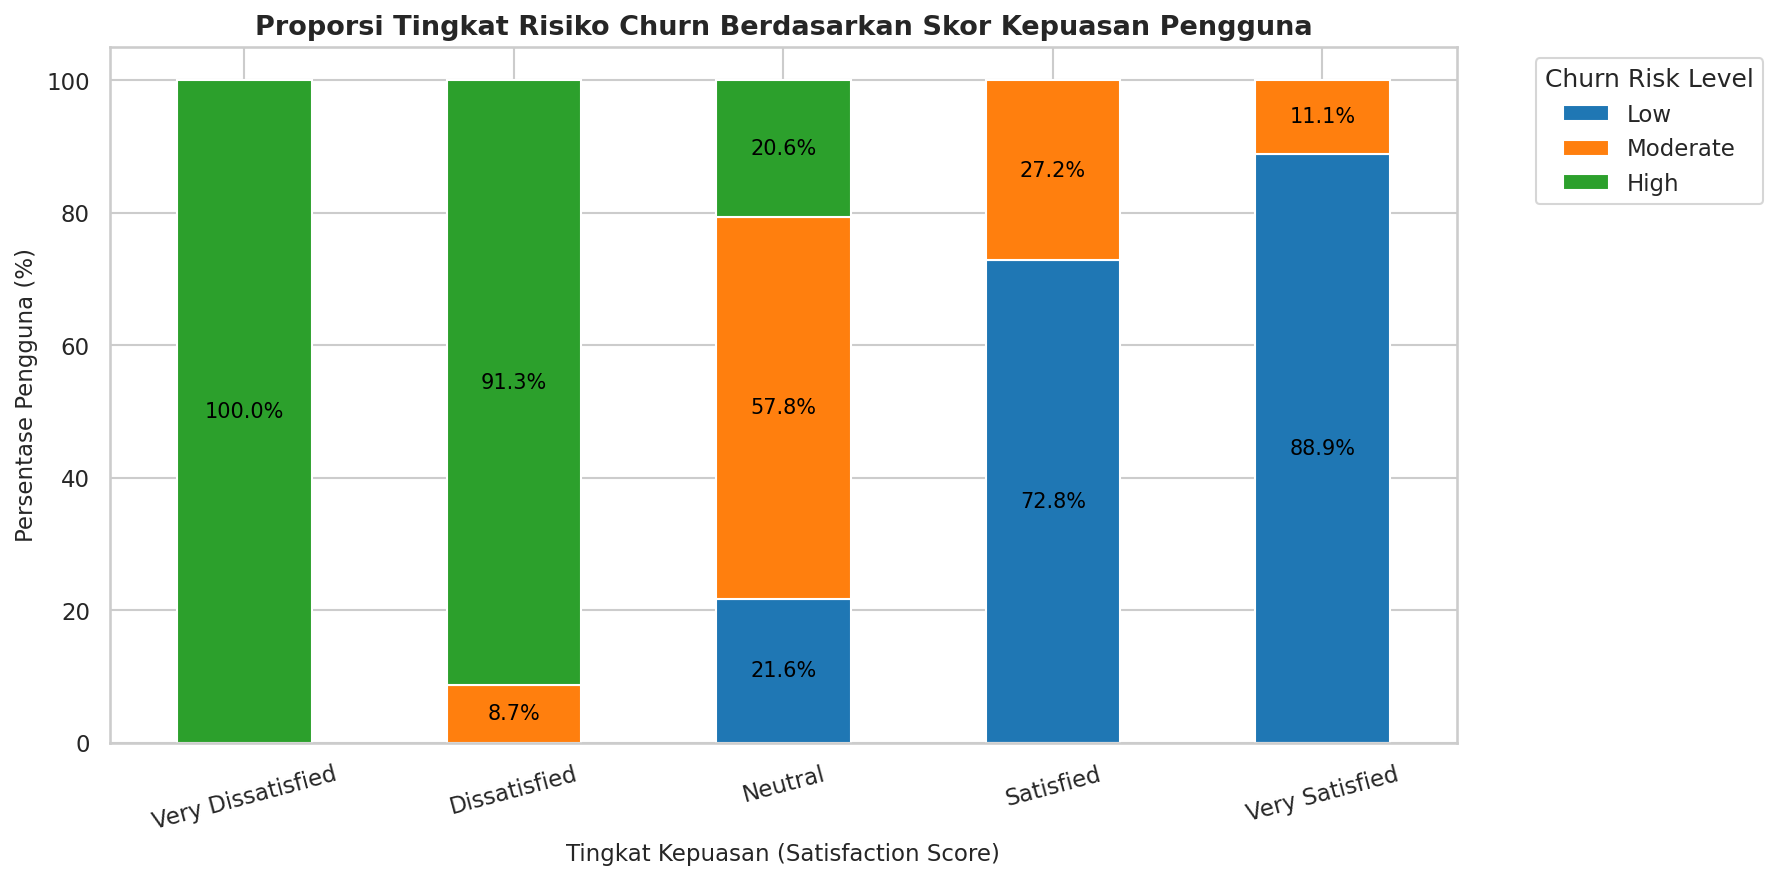

In [472]:
# Visualisasi 1: Stacked Bar Chart - Proporsi Churn Risk per Satisfaction Score
fig, ax = plt.subplots(figsize=(12, 6))
sat_churn_ct = (
    pd.crosstab(
        df_processed['satisfaction_score'],
        df_processed['churn_risk_level'],
        normalize='index',
    )[churn_order]
    * 100
)
sat_churn_ct = sat_churn_ct.reindex(satisfaction_order)
sat_churn_ct.plot(kind='bar', stacked=True, ax=ax)

plt.title(
    'Proporsi Tingkat Risiko Churn Berdasarkan Skor Kepuasan Pengguna',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Tingkat Kepuasan (Satisfaction Score)', fontsize=11)
plt.ylabel('Persentase Pengguna (%)', fontsize=11)
plt.legend(title='Churn Risk Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15)

for p in ax.patches:
  height = p.get_height()
  width = p.get_width()
  x, y = p.get_xy()
  if height > 0:
    ax.annotate(
        f'{height:.1f}%',
        (x + width / 2.0, y + height / 2.0),
        ha='center',
        va='center',
        fontsize=10,
        color='black'
    )

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 1: Stacked Bar Chart - Proporsi Churn Risk per Satisfaction Score:**
- Hubungan Berbanding Lurus: Semakin tinggi tingkat kepuasan pengguna, semakin rendah risiko pengguna berhenti berlangganan (churn).
- Pengguna Sangat Tidak Puas (Very Dissatisfied): Seluruh pengguna (100.0%) pada kategori ini berada pada risiko churn yang tinggi (High).
- Pengguna Tidak Puas (Dissatisfied): Didominasi oleh risiko churn tinggi (High) sebesar 91.3%, sedangkan sisanya (8.7%) berada pada risiko sedang (Moderate).
- Pengguna Netral (Neutral): Mayoritas berada pada risiko sedang (Moderate) sebesar 57.8%, diikuti oleh risiko rendah (Low) 21.6% dan risiko tinggi (High) 20.6%.
- Pengguna Puas & Sangat Puas (Satisfied & Very Satisfied): Didominasi oleh risiko churn yang rendah (Low), yaitu mencapai 72.8% pada pengguna Satisfied dan 88.9% pada pengguna Very Satisfied, tanpa ada risiko churn tinggi (High).  

/tmp/ipykernel_92946/1241947968.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


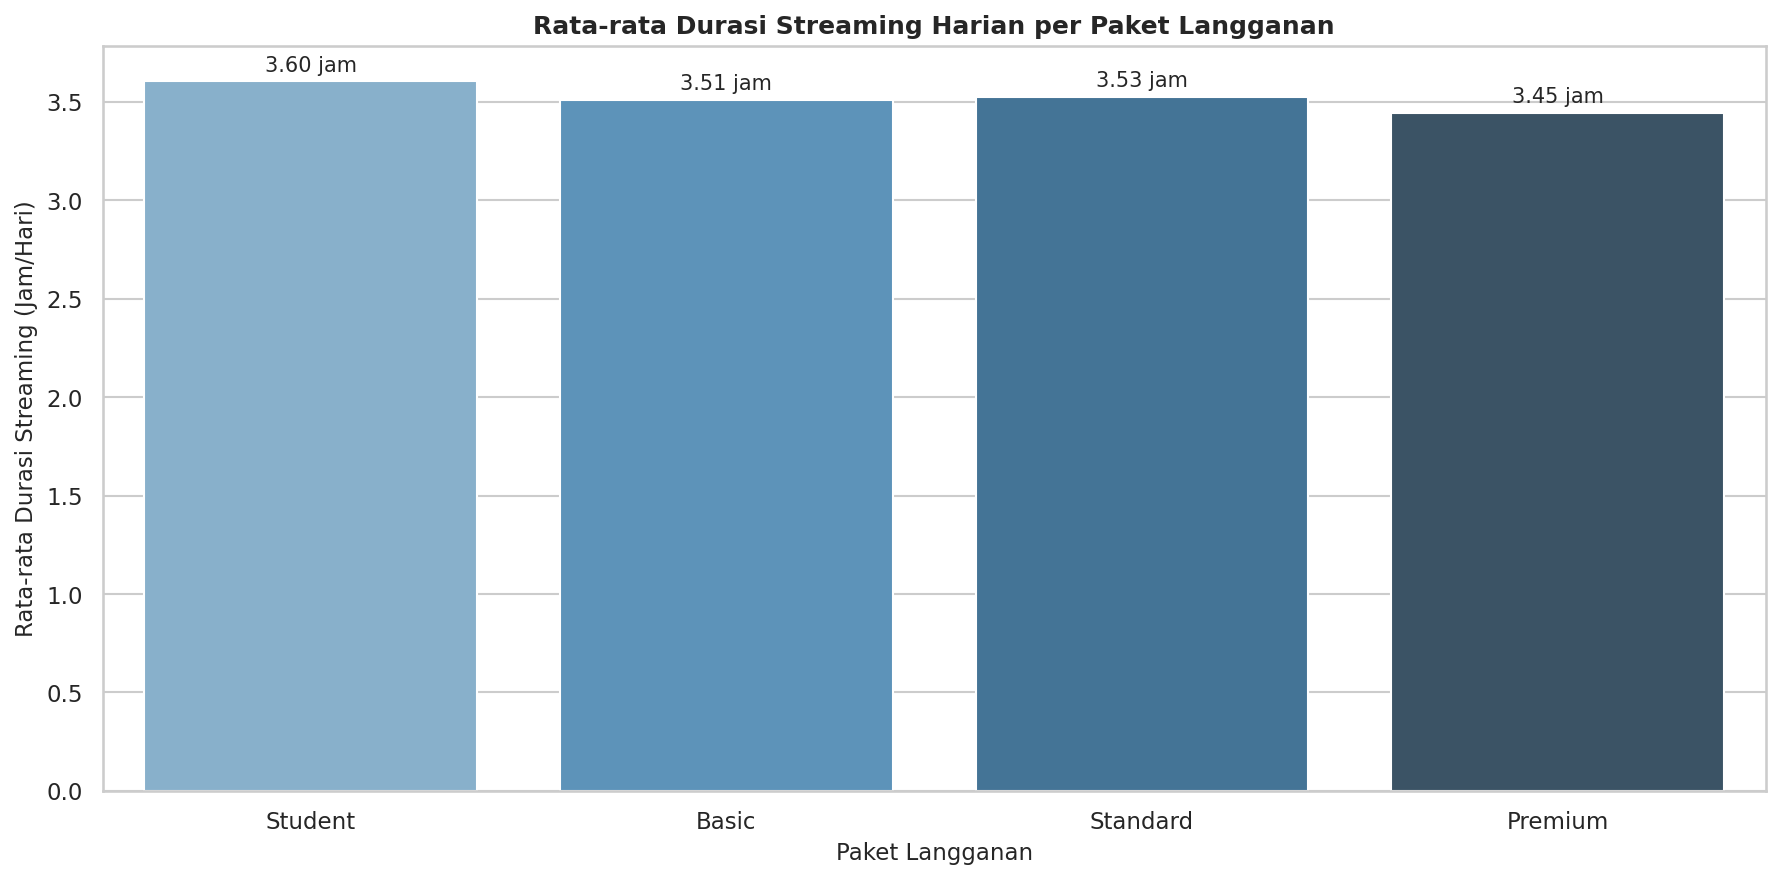

In [473]:
# Visualisasi 2: Bar Chart - Durasi Streaming Harian per Paket
plt.figure(figsize=(12, 6))
ax1 = sns.barplot(
    data=df_processed,
    x='subscription_plan',
    y='daily_streaming_hours',
    order=plan_order,
    palette='Blues_d',
    errorbar=None,
)

plt.title(
    'Rata-rata Durasi Streaming Harian per Paket Langganan',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Paket Langganan', fontsize=11)
plt.ylabel('Rata-rata Durasi Streaming (Jam/Hari)', fontsize=11)

for p in ax1.patches:
  height = p.get_height()
  if height > 0:
    ax1.annotate(
        f'{height:.2f} jam',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points',
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 2: Bar Chart - Durasi Streaming Harian per Paket:**
- Durasi Relatif Seragam: Rata-rata durasi streaming harian di seluruh paket langganan relatif sama dan berada di kisaran 3,45 hingga 3,60 jam per hari.
- Pengguna Paket Student Paling Lama: Pelanggan dengan paket Student mencatatkan durasi menonton paling tinggi, yaitu rata-rata 3,60 jam per hari.
- Pengguna Paket Premium Paling Singkat: Pelanggan paket Premium memiliki durasi menonton paling rendah dibanding paket lainnya, yaitu rata-rata 3,45 jam per hari.
- Paket Basic dan Standard Relatif Seimbang: Pengguna paket Standard menonton rata-rata 3,53 jam per hari, sedikit lebih tinggi dari pengguna paket Basic yang mencatatkan rata-rata 3,51 jam per hari.
- Paket Langganan Tidak Membatasi Konsumsi: Jenis/tingkatan paket langganan tidak memberikan perbedaan yang signifikan terhadap intensitas atau waktu yang dihabiskan pengguna untuk menonton setiap harinya.  

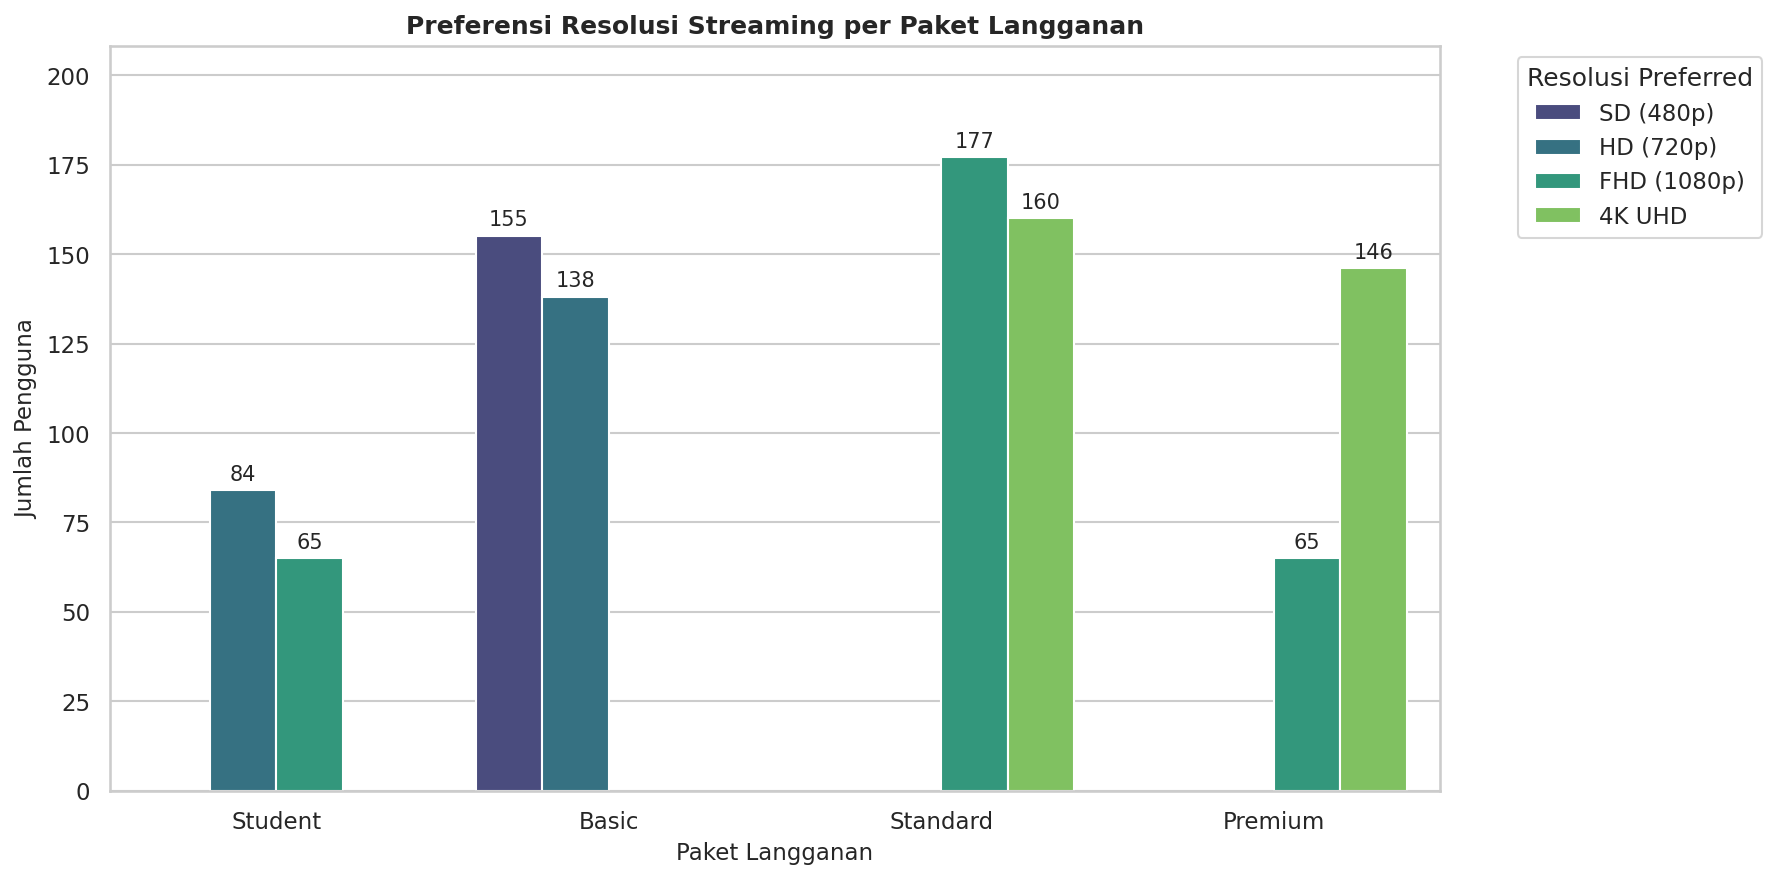

In [474]:
# Visualisasi 3: Grouped Countplot - Preferensi Resolusi per Paket
plt.figure(figsize=(12, 6))
quality_order = ['SD (480p)', 'HD (720p)', 'FHD (1080p)', '4K UHD']
ax2 = sns.countplot(
    data=df_processed,
    x='subscription_plan',
    hue='streaming_quality_preference',
    order=plan_order,
    hue_order=quality_order,
    palette='viridis',
)

plt.title(
    'Preferensi Resolusi Streaming per Paket Langganan',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Paket Langganan', fontsize=11)
plt.ylabel('Jumlah Pengguna', fontsize=11)
plt.legend(title='Resolusi Preferred', bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.12)

for p in ax2.patches:
  height = p.get_height()
  if height > 0:
    ax2.annotate(
        f'{int(height)}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points',
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretasi Visualisasi 3: Grouped Countplot - Preferensi Resolusi per Paket:**
- Segmentasi Resolusi Eksklusif: Setiap paket langganan hanya menawarkan dua pilihan resolusi tertentu yang sesuai dengan tingkatannya.
- Paket Student: Pengguna hanya memilih resolusi kualitas menengah, yaitu HD (720p) sebanyak 84 pengguna dan FHD (1080p) sebanyak 65 pengguna.
- Paket Basic: Didominasi oleh resolusi standar dan menengah, yaitu SD (480p) sebanyak 155 pengguna dan HD (720p) sebanyak 138 pengguna.
- Paket Standard: Menjadi paket dengan jumlah peminat kualitas tinggi terbanyak, di mana FHD (1080p) dipilih oleh 177 pengguna dan 4K UHD oleh 160 pengguna.
- Paket Premium: Mayoritas penggunanya memilih resolusi tertinggi 4K UHD (146 pengguna), sementara sisanya menggunakan FHD (1080p) (65 pengguna).